# Pass Rush vs. Coverage: Which One Drives NFL Defensive Efficiency?

**Question:** When an NFL defense is good, is it mostly because it **pressures the quarterback**, or because its **coverage** shuts down receivers?

**How to use this notebook:** every gray code box has a plain-English explanation right above it.
Read the explanation, then run the box (click it and press **Shift + Enter**). To run everything from top to bottom, use **Run All** in the toolbar.
The first run downloads about 100 MB of data, so it may take a minute or two.

**Roadmap**
1. What the data source is and how we get it
2. Download the raw data and look at it
3. Understand the raw data's structure
4. Clean it into one simple table (one row per team per season)
5. Check that the numbers look right
6. Measure which factor matters more
7. One chart
8. Summary

## Step 1 — The source: nflverse and `nflreadpy`

**What it is.** [nflverse](https://nflverse.nflverse.com/) is a free, open-source project that collects and publishes NFL data: every play of every game, player stats, rosters, and more. The files are hosted publicly on GitHub and refreshed during the season.

**How we access it.** `nflreadpy` ([docs](https://nflreadpy.nflverse.com/)) is the official Python package for downloading those files. Instead of visiting a website and clicking "download", we call a function such as `nfl.load_pbp(seasons=[2024])` and get the data back as a table.

**The two datasets we need**

| Function | What it gives us | Why we need it |
|---|---|---|
| `load_pbp()` | **Play-by-play**: one row per play, including **EPA** (explained below) | To measure how efficient each defense is |
| `load_participation()` | Extra charting for each play, including **`was_pressure`** (was the QB pressured?) | To measure pass rush, and to split passes into "pressured" vs. "clean pocket" |

**Why only 2023–2025?** The `was_pressure` flag is filled in for every play starting in 2023. Earlier seasons have it on only about 38% of plays, which would make the comparison unreliable. Three full seasons gives us 32 teams × 3 = **96 team-seasons**.

**Key term: EPA (Expected Points Added).** Before each play, a model estimates how many points the offense is expected to score from that spot (based on down, distance, field position, and so on). EPA is how much that expectation changed because of the play. A 40-yard catch might be +2.5 EPA; a sack might be −1.5. For a **defense, lower EPA allowed is better**. Averaging EPA per play is the standard way analysts measure efficiency.

The code below loads the tools we use:
- `nflreadpy` downloads the data
- `pandas` works with tables (like Excel in code)
- `matplotlib` draws the chart
- `pathlib` creates folders for the output files

It also sets which seasons we want.

In [1]:
import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEASONS = [2023, 2024, 2025]

# Folders where we will save the clean table and the chart
Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
print("Tools loaded. Seasons:", SEASONS)

Tools loaded. Seasons: [2023, 2024, 2025]


## Step 2 — Download the raw data

Now we download both datasets for 2023–2025. `nflreadpy` returns data in a format called *polars*. We convert it with `.to_pandas()` because pandas is the more common table tool and has more help online.

After downloading, we print the **shape** (rows × columns) of each table, so we know how big it is.

In [2]:
pbp_raw = nfl.load_pbp(seasons=SEASONS).to_pandas()
participation_raw = nfl.load_participation(seasons=SEASONS).to_pandas()

print(f"Play-by-play:   {pbp_raw.shape[0]:,} rows x {pbp_raw.shape[1]} columns")
print(f"Participation:  {participation_raw.shape[0]:,} rows x {participation_raw.shape[1]} columns")

Play-by-play:   147,928 rows x 372 columns
Participation:  137,271 rows x 26 columns


## Step 3 — What the raw data looks like

The play-by-play table has **one row per play** and almost **400 columns**. We only need a handful of them. Below we display a few real plays, showing just the columns we care about:

| Column | Meaning |
|---|---|
| `game_id`, `play_id` | Together, these identify one exact play (like an address) |
| `season`, `week`, `season_type` | When it happened. `REG` = regular season, `POST` = playoffs |
| `posteam` / `defteam` | The team on offense / defense |
| `play_type` | `pass`, `run`, `punt`, `kickoff`, `no_play` (penalty), etc. |
| `qb_dropback` | 1 if the QB dropped back to pass (includes sacks and scrambles) |
| `sack` | 1 if the play was a sack |
| `epa` | Expected Points Added for the offense on that play |
| `desc` | The plain-text description of the play |

In [3]:
pbp_cols = ["game_id", "play_id", "season", "week", "season_type", "posteam", "defteam",
            "play_type", "qb_dropback", "sack", "epa", "desc"]
pbp_raw[pbp_cols].dropna(subset=["play_type"]).head(8)

,game_id,play_id,season,week,season_type,posteam,defteam,play_type,qb_dropback,sack,epa,desc
1,2023_01_ARI_WAS,39.0,2023,1,REG,WAS,ARI,kickoff,0.0,0.0,0.000000,5-M.Prater kicks 65 yards from ARI 35 to end z...
2,2023_01_ARI_WAS,55.0,2023,1,REG,WAS,ARI,run,0.0,0.0,-0.336103,(15:00) (Shotgun) 8-B.Robinson right tackle to...
3,2023_01_ARI_WAS,77.0,2023,1,REG,WAS,ARI,pass,1.0,0.0,0.703308,(14:30) (Shotgun) 14-S.Howell pass short right...
4,2023_01_ARI_WAS,102.0,2023,1,REG,WAS,ARI,run,0.0,0.0,0.469799,(13:55) 23-C.Rodriguez left guard to WAS 36 fo...
5,2023_01_ARI_WAS,124.0,2023,1,REG,WAS,ARI,pass,1.0,0.0,-0.521544,(13:16) (Shotgun) 14-S.Howell pass incomplete ...
6,2023_01_ARI_WAS,147.0,2023,1,REG,WAS,ARI,pass,1.0,0.0,1.173155,(13:12) 14-S.Howell pass short middle to 1-J.D...
7,2023_01_ARI_WAS,172.0,2023,1,REG,WAS,ARI,pass,1.0,0.0,-0.515452,(12:34) (Shotgun) 14-S.Howell pass short left ...
8,2023_01_ARI_WAS,197.0,2023,1,REG,WAS,ARI,pass,1.0,0.0,-0.872005,(11:56) (Shotgun) 14-S.Howell pass incomplete ...


The participation table also has **one row per play**. It uses the same game and play IDs (here the game column is called `nflverse_game_id`), so we can **match each play across the two tables**. The column we need is `was_pressure`: `True` if the quarterback was pressured (hurried, hit, or sacked), `False` if he had a clean pocket.

Below are a few rows, along with a count of how often each value appears.

In [4]:
participation_raw[["nflverse_game_id", "play_id", "possession_team",
                   "number_of_pass_rushers", "was_pressure"]].head(8)

,nflverse_game_id,play_id,possession_team,number_of_pass_rushers,was_pressure
0,2023_01_ARI_WAS,39.0,WAS,0.0,False
1,2023_01_ARI_WAS,55.0,WAS,0.0,False
2,2023_01_ARI_WAS,77.0,WAS,4.0,False
3,2023_01_ARI_WAS,102.0,WAS,0.0,False
4,2023_01_ARI_WAS,124.0,WAS,4.0,False
5,2023_01_ARI_WAS,147.0,WAS,5.0,False
6,2023_01_ARI_WAS,172.0,WAS,5.0,False
7,2023_01_ARI_WAS,197.0,WAS,4.0,False


In [5]:
participation_raw["was_pressure"].value_counts(dropna=False)

was_pressure
False    116730
True      20518
None         23
Name: count, dtype: int64

**What this tells us:** most plays have `was_pressure = False`. That makes sense, because running plays can never be "pressured", and most passes are thrown from a clean pocket. A few plays are blank (`None`). They are rare, and we'll confirm in Step 5 that none of them fall on the pass plays we use.

## Step 4 — Clean the data into one simple table

**4a. Keep only real, comparable plays.** We keep:
- **Regular season only.** Playoff teams play extra games, which would make teams hard to compare.
- **Only `pass` and `run` plays.** We drop punts, kickoffs, field goals, kneel-downs, and plays erased by penalties.
- **Only plays where EPA was calculated.** A handful of odd plays have no EPA.

**4b. Attach the pressure flag.** We match each play to its participation row by game ID and play ID. This is a *merge*, like VLOOKUP in Excel.

In [6]:
plays = pbp_raw[
    (pbp_raw["season_type"] == "REG")
    & (pbp_raw["play_type"].isin(["pass", "run"]))
    & (pbp_raw["epa"].notna())
][["game_id", "play_id", "season", "week", "defteam", "play_type", "qb_dropback", "sack", "epa"]]

plays = plays.merge(
    participation_raw[["nflverse_game_id", "play_id", "was_pressure"]],
    left_on=["game_id", "play_id"],
    right_on=["nflverse_game_id", "play_id"],
    how="left",
).drop(columns="nflverse_game_id")

# Store the flag as a number (1 = pressured, 0 = clean pocket) so averages give a rate
plays["was_pressure"] = plays["was_pressure"].astype(float)

dropbacks = plays[plays["qb_dropback"] == 1]

print(f"Plays kept:        {len(plays):,}")
print(f"  of which passes: {len(dropbacks):,} (QB dropbacks)")

Plays kept:        100,368
  of which passes: 60,815 (QB dropbacks)


**4c. Build one row per defense per season.** For each team and season we calculate three numbers:

| New column | How it's calculated | What it represents | Better is… |
|---|---|---|---|
| `epa_per_play_allowed` | Average EPA on **all** run + pass plays against this defense | **Overall defensive efficiency** (the outcome we're explaining) | Lower |
| `pressure_rate` | Share of opponent dropbacks where the QB was pressured | **Pass rush** | Higher |
| `clean_pocket_epa_allowed` | Average EPA on dropbacks where the QB was **not** pressured | **Coverage.** When the rush doesn't get there, the QB has time, so the result depends mostly on whether receivers get open. | Lower |

We also keep the number of plays and dropbacks, and the EPA allowed when the QB **was** pressured, so we can check that the numbers are reasonable.

Finally, we save the table as a CSV file (`data/team_defense_2023_2025.csv`) that you can open in Excel.

In [7]:
overall = plays.groupby(["season", "defteam"]).agg(
    plays=("epa", "size"),
    epa_per_play_allowed=("epa", "mean"),
)

rush = dropbacks.groupby(["season", "defteam"]).agg(
    dropbacks=("epa", "size"),
    pressure_rate=("was_pressure", "mean"),
)

clean = (dropbacks[dropbacks["was_pressure"] == 0]
         .groupby(["season", "defteam"])["epa"].mean()
         .rename("clean_pocket_epa_allowed"))

pressured = (dropbacks[dropbacks["was_pressure"] == 1]
             .groupby(["season", "defteam"])["epa"].mean()
             .rename("pressured_epa_allowed"))

team_defense = (overall.join(rush).join(clean).join(pressured)
                .reset_index()
                .rename(columns={"defteam": "team"}))

team_defense.to_csv("data/team_defense_2023_2025.csv", index=False)
team_defense.round(3).head(10)

,season,team,plays,epa_per_play_allowed,dropbacks,pressure_rate,clean_pocket_epa_allowed,pressured_epa_allowed
0,2023,ARI,1047,0.085,571,0.256,0.386,-0.443
1,2023,ATL,1072,-0.059,623,0.292,0.257,-0.529
2,2023,BAL,1104,-0.149,736,0.287,0.021,-0.708
3,2023,BUF,1007,-0.074,648,0.316,0.127,-0.522
4,2023,CAR,981,0.023,522,0.245,0.240,-0.666
5,2023,CHI,1029,-0.041,680,0.247,0.127,-0.343
6,2023,CIN,1049,0.034,647,0.304,0.372,-0.619
7,2023,CLE,991,-0.186,615,0.328,-0.056,-0.582
8,2023,DAL,1003,-0.114,591,0.338,0.163,-0.639
9,2023,DEN,1072,0.019,642,0.282,0.289,-0.477


## Step 5 — Check that the numbers look right

Before trusting any results, we run some sanity checks. Each line below compares a number to what we'd expect, then prints **PASS** or **CHECK**:

1. **Every team-season is present.** We should have exactly 32 teams × 3 seasons = 96 rows, with no blanks.
2. **No missing pressure flags** on the pass plays we use.
3. **Play counts are realistic.** A defense faces about 60–65 run/pass plays per game, so roughly 950–1,150 over a 17-game season. About 60% of those should be dropbacks.
4. **The league pressure rate is realistic.** Public charting services usually put it at about 30–35%.
5. **Sacks are counted as pressures.** By definition, every sack should be a pressure.
6. **Pressure hurts offenses.** Pressured dropbacks should have much lower EPA than clean ones.
7. **League average EPA per play is close to 0.** EPA is built so that it averages out near zero.

In [8]:
def check(label, ok, detail):
    print(f"[{'PASS' if ok else 'CHECK'}] {label}: {detail}")

per_season = team_defense.groupby("season").size()
check("1. 32 teams in every season", (per_season == 32).all() and len(team_defense) == 96,
      dict(per_season))
check("   no blank values in the table", team_defense.isna().sum().sum() == 0,
      f"{team_defense.isna().sum().sum()} blanks")

missing = dropbacks["was_pressure"].isna().mean()
check("2. pressure flag present on dropbacks", missing == 0, f"{missing:.2%} missing")

check("3. plays per team-season in 950-1150", team_defense["plays"].between(900, 1200).all(),
      f"range {team_defense['plays'].min()}-{team_defense['plays'].max()}")
share_db = team_defense["dropbacks"].sum() / team_defense["plays"].sum()
check("   share of plays that are dropbacks ~60%", 0.55 < share_db < 0.65, f"{share_db:.1%}")

league_pr = dropbacks["was_pressure"].mean()
check("4. league pressure rate 25-40%", 0.25 < league_pr < 0.40, f"{league_pr:.1%}")

sack_pr = dropbacks.loc[dropbacks["sack"] == 1, "was_pressure"].mean()
check("5. sacks flagged as pressure", sack_pr > 0.98, f"{sack_pr:.1%} of sacks")

epa_by = dropbacks.groupby("was_pressure")["epa"].mean()
check("6. pressured EPA far below clean EPA", epa_by[1] < epa_by[0] - 0.3,
      f"pressured {epa_by[1]:+.2f} vs clean {epa_by[0]:+.2f} EPA per dropback")

league_epa = plays["epa"].mean()
check("7. league EPA per play near 0", abs(league_epa) < 0.05, f"{league_epa:+.3f}")

[PASS] 1. 32 teams in every season: {2023: np.int64(32), 2024: np.int64(32), 2025: np.int64(32)}
[PASS]    no blank values in the table: 0 blanks
[PASS] 2. pressure flag present on dropbacks: 0.00% missing
[PASS] 3. plays per team-season in 950-1150: range 950-1136
[PASS]    share of plays that are dropbacks ~60%: 60.6%
[PASS] 4. league pressure rate 25-40%: 30.0%
[PASS] 5. sacks flagged as pressure: 100.0% of sacks
[PASS] 6. pressured EPA far below clean EPA: pressured -0.45 vs clean +0.23 EPA per dropback
[PASS] 7. league EPA per play near 0: -0.005


**One more "smell test": do the best defenses match reality?** If the table is right, the top of the list should look like the defenses fans and analysts praised in those years. For example, the 2023 Browns led the league in total defense, and the 2023 Ravens allowed the fewest points.

In [9]:
cols = ["season", "team", "epa_per_play_allowed", "pressure_rate", "clean_pocket_epa_allowed"]
print("Five BEST defenses (lowest EPA per play allowed):")
display(team_defense.nsmallest(5, "epa_per_play_allowed")[cols].round(3))
print("Five WORST defenses:")
display(team_defense.nlargest(5, "epa_per_play_allowed")[cols].round(3))

Five BEST defenses (lowest EPA per play allowed):


,season,team,epa_per_play_allowed,pressure_rate,clean_pocket_epa_allowed
7,2023,CLE,-0.186,0.328,-0.056
2,2023,BAL,-0.149,0.287,0.021
76,2025,HOU,-0.131,0.300,0.129
24,2023,NYJ,-0.119,0.328,0.089
41,2024,DEN,-0.118,0.384,0.175


Five WORST defenses:


,season,team,epa_per_play_allowed,pressure_rate,clean_pocket_epa_allowed
72,2025,DAL,0.167,0.320,0.476
36,2024,CAR,0.160,0.225,0.312
88,2025,NYJ,0.147,0.238,0.424
95,2025,WAS,0.143,0.311,0.502
70,2025,CIN,0.130,0.298,0.353


## Step 6 — Which matters more?

We'll answer the question three ways, from simplest to most careful.

**6a. Correlation.** A correlation (`r`) runs from −1 to +1 and measures how closely two numbers move together. Remember that lower EPA allowed is better. So a good pass rush should show a **negative** r (more pressure → less EPA allowed), and good coverage should show a **positive** r (less clean-pocket EPA allowed → less EPA allowed overall). The bigger the number, ignoring the sign, the stronger the link. **r²** is the share of the differences between defenses that this one factor "explains".

In [10]:
r_pressure = team_defense["pressure_rate"].corr(team_defense["epa_per_play_allowed"])
r_coverage = team_defense["clean_pocket_epa_allowed"].corr(team_defense["epa_per_play_allowed"])
r_between = team_defense["pressure_rate"].corr(team_defense["clean_pocket_epa_allowed"])

print(f"Pass rush (pressure rate) vs efficiency: r = {r_pressure:+.2f}  ->  explains {r_pressure**2:.0%}")
print(f"Coverage (clean-pocket EPA) vs efficiency: r = {r_coverage:+.2f}  ->  explains {r_coverage**2:.0%}")
print(f"Pass rush vs coverage (are they linked?):  r = {r_between:+.2f}")

Pass rush (pressure rate) vs efficiency: r = -0.38  ->  explains 14%
Coverage (clean-pocket EPA) vs efficiency: r = +0.86  ->  explains 73%
Pass rush vs coverage (are they linked?):  r = -0.17


**6b. Both at once, on the same scale.** Pressure rate is a percentage and clean-pocket EPA is in points, so we can't compare them directly. We convert each to **standard deviations** ("how far above or below an average team is this defense?") and fit a simple regression that uses both at the same time.

Each result answers: *"If a defense improves this factor by one standard deviation (about the gap between an average team and a top-10 team), how much does its EPA per play allowed drop, holding the other factor constant?"*

In [11]:
from sklearn.linear_model import LinearRegression

def standardize(s):
    return (s - s.mean()) / s.std()

X = pd.DataFrame({
    "pass_rush": standardize(team_defense["pressure_rate"]),
    # flip the sign so that "+1" means BETTER coverage, just like "+1" means better pass rush
    "coverage": -standardize(team_defense["clean_pocket_epa_allowed"]),
})
y = team_defense["epa_per_play_allowed"]

model = LinearRegression().fit(X, y)
effects = pd.Series(-model.coef_, index=X.columns)   # positive = EPA per play saved

print("EPA per play SAVED by a +1 standard-deviation improvement:")
for name, val in effects.items():
    print(f"  {name:10s} {val:.3f}")
print(f"Coverage effect is {effects['coverage'] / effects['pass_rush']:.1f}x the pass-rush effect")
print(f"Together they explain {model.score(X, y):.0%} of the differences between defenses")

EPA per play SAVED by a +1 standard-deviation improvement:
  pass_rush  0.017
  coverage   0.060
Coverage effect is 3.5x the pass-rush effect
Together they explain 79% of the differences between defenses


**6c. A fairness check (split-half test).** There is a catch in 6a and 6b. Clean-pocket passes are themselves about 40% of the plays that make up a defense's overall EPA, so the coverage number gets a head start: it is partly measuring the outcome directly.

To remove that overlap, we **measure the two skills in odd-numbered weeks and grade the defense in even-numbered weeks**. Now none of the plays used to measure coverage or pass rush are counted in the outcome. This test also asks a more useful question: *which skill better predicts how a defense will play in **other** games?*

In [12]:
odd = plays["week"] % 2 == 1

skills_odd = pd.DataFrame({
    "pressure_rate": dropbacks[dropbacks["week"] % 2 == 1].groupby(["season", "defteam"])["was_pressure"].mean(),
    "clean_pocket_epa_allowed": dropbacks[(dropbacks["week"] % 2 == 1) & (dropbacks["was_pressure"] == 0)]
                                .groupby(["season", "defteam"])["epa"].mean(),
})
outcome_even = plays[~odd].groupby(["season", "defteam"])["epa"].mean().rename("epa_even_weeks")
split = skills_odd.join(outcome_even)

r_p_split = split["pressure_rate"].corr(split["epa_even_weeks"])
r_c_split = split["clean_pocket_epa_allowed"].corr(split["epa_even_weeks"])
print("Skills measured in ODD weeks vs efficiency in EVEN weeks:")
print(f"  Pass rush: r = {r_p_split:+.2f}  ->  explains {r_p_split**2:.0%}")
print(f"  Coverage:  r = {r_c_split:+.2f}  ->  explains {r_c_split**2:.0%}")

Skills measured in ODD weeks vs efficiency in EVEN weeks:
  Pass rush: r = -0.12  ->  explains 1%
  Coverage:  r = +0.21  ->  explains 4%


## Step 7 — The chart

Two side-by-side panels, one dot per team-season (96 dots each). Both panels share the same vertical axis: **overall defensive efficiency**. The axes are oriented so that **up and to the right is always "better"**:
- **Left panel:** pass rush (higher pressure rate is further right)
- **Right panel:** coverage (less EPA allowed on clean-pocket passes is further right)

The dots in the **tighter** panel belong to the factor that is more closely tied to overall efficiency. The three best defenses are labeled. The chart is saved to `figures/pressure_vs_coverage.png`.

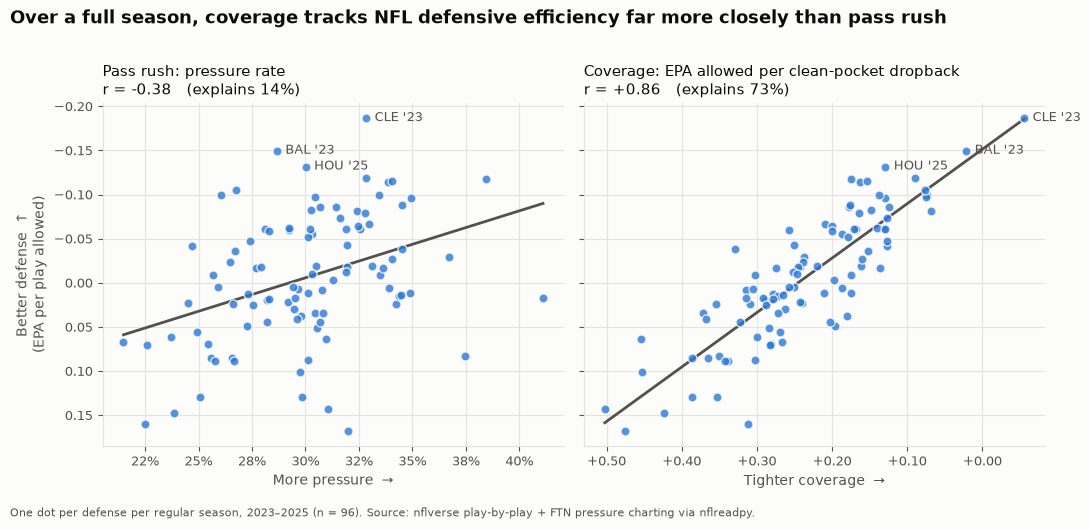

In [13]:
import numpy as np

BLUE, INK, INK_2, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True, facecolor=SURFACE)
panels = [
    ("pressure_rate", "Pass rush: pressure rate", r_pressure, lambda v: f"{v:.0%}"),
    ("clean_pocket_epa_allowed", "Coverage: EPA allowed per clean-pocket dropback", r_coverage, lambda v: f"{v:+.2f}"),
]
best = team_defense.nsmallest(3, "epa_per_play_allowed")

for ax, (col, xlabel, r, fmt) in zip(axes, panels):
    x, y = team_defense[col], team_defense["epa_per_play_allowed"]
    ax.set_facecolor(SURFACE)
    ax.scatter(x, y, s=42, color=BLUE, alpha=0.8, edgecolor=SURFACE, linewidth=1, zorder=3)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, slope * xs + intercept, color=INK_2, linewidth=2, zorder=2)
    for _, row in best.iterrows():
        ax.annotate(f"{row['team']} '{str(row['season'])[2:]}", (row[col], row["epa_per_play_allowed"]),
                    xytext=(6, -2), textcoords="offset points", fontsize=9, color=INK_2)
    ax.set_title(f"{xlabel}\nr = {r:+.2f}   (explains {r**2:.0%})", fontsize=11, color=INK, loc="left")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, fmt=fmt: fmt(v)))
    ax.grid(True, color=GRID, linewidth=0.8, zorder=0)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=9)

axes[0].set_xlabel("More pressure  →", color=INK_2)
axes[1].set_xlabel("Tighter coverage  →", color=INK_2)
axes[1].invert_xaxis()              # lower clean-pocket EPA = better coverage, so put it on the right
axes[0].invert_yaxis()              # lower EPA allowed = better defense, so put it at the top
axes[0].set_ylabel("Better defense  ↑\n(EPA per play allowed)", color=INK_2)

fig.suptitle("Over a full season, coverage tracks NFL defensive efficiency far more closely than pass rush",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.text(0.01, 0.005, "One dot per defense per regular season, 2023–2025 (n = 96). "
         "Source: nflverse play-by-play + FTN pressure charting via nflreadpy.",
         fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig("figures/pressure_vs_coverage.png", dpi=200, facecolor=SURFACE)
plt.show()

## Step 8 — Summary

**What we did**
1. **Source.** We downloaded free NFL data from nflverse using the `nflreadpy` Python package: play-by-play data (with EPA) and play-level charting that marks whether the QB was pressured.
2. **Raw data.** Both tables have one row per play (about 49,000 plays per season). Play-by-play has almost 400 columns, and we used 9 of them.
3. **Cleaning.** We kept regular-season run and pass plays from 2023–2025, attached the pressure flag to each play, and summarized everything into **one row per defense per season** (96 rows). The result is saved in `data/team_defense_2023_2025.csv`.
4. **Checks.** All 96 team-seasons are present, there are no missing values, and play counts, the league pressure rate (~30%), and league EPA (~0) are realistic. Sacks are counted as pressures, and the best defenses on our list match the reputations of those years' defenses.
5. **Analysis and chart.** We compared how closely pass rush and coverage line up with overall defensive efficiency, first using all games, then with a fair split-half test.

**What we found** (exact numbers are printed in Step 6)
- **Coverage is the stronger signal.** Over full seasons, coverage (clean-pocket EPA allowed) lines up with overall efficiency at r = +0.86, explaining about 73% of the differences between defenses. Pressure rate comes in at r = −0.38, explaining about 14%. With both factors on the same scale, a one-standard-deviation improvement in coverage saves about 3.5× as much EPA per play as the same improvement in pass rush.
- **Pressure still matters, and it matters per play.** A pressured dropback is a disaster for offenses (−0.45 EPA vs. +0.23 when the pocket is clean). But most defenses pressure the QB on 28–32% of dropbacks, so differences in pressure rate separate defenses less than differences in coverage do.
- **The fairness test shrinks the gap a lot.** When we measure the skills in odd weeks and grade the defense in even weeks (no shared plays), coverage still comes out ahead (r = +0.21 vs. −0.12). But both links become weak. Much of coverage's big full-season edge came from the overlap between the coverage measure and the outcome. Half a season of games is also a small sample, so week-to-week defensive results are noisy.

**Bottom line:** in 2023–2025, defenses that were efficient were mostly the ones that held up in coverage when the QB had time, more than the ones that got home most often. The evidence for coverage's edge is solid in direction, but its size is smaller than the full-season numbers alone suggest.

**Limits to keep in mind**
- "Coverage" here is inferred from results (clean-pocket EPA), not seen directly. It also reflects the opposing QB and receivers and some luck, such as dropped interceptions.
- Pass rush and coverage feed each other. Sticky coverage gives the rush extra time to arrive ("coverage sacks"), and a fast rush makes coverage look better. Our measures separate them only partly.
- This is three seasons and 96 team-seasons: enough to see a clear pattern, but not proof of cause and effect.